**Name:** Mohaiya aldossary  
**Student ID:** 2230004579

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="assets/attention.png" width="700">

## Step 1 — Import libraries

In [1]:
%pip -q install torch "tensorflow==2.16.1" "numpy>=1.26,<2" "pandas>=2.1,<4" matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ezio9\OneDrive\Desktop\IAU\NLP\NLP lab\.lab_work\venv10\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

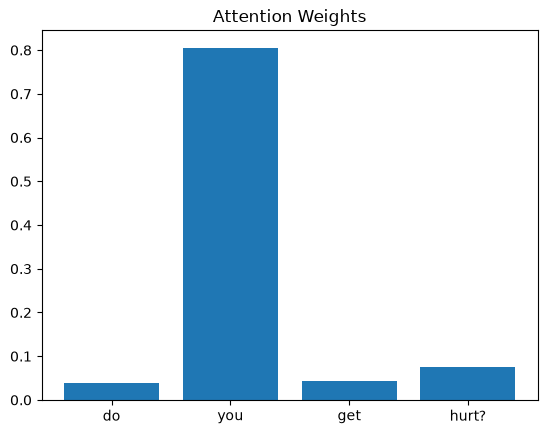

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention: you (0.8050)


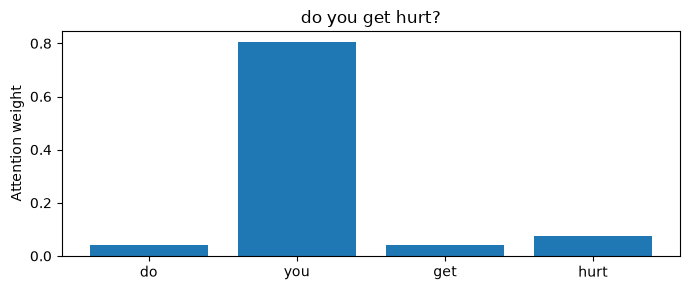

Question: how old are you?
Highest attention: how (0.3111)


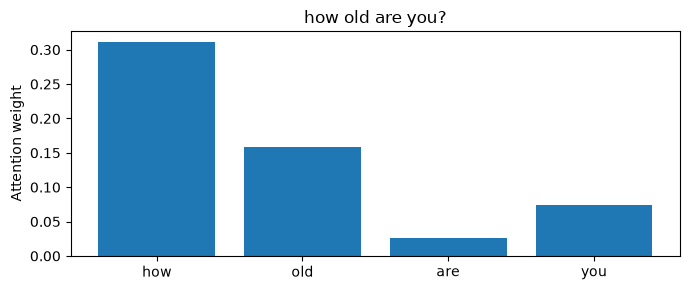

Question: who created you?
Highest attention: you (0.4792)


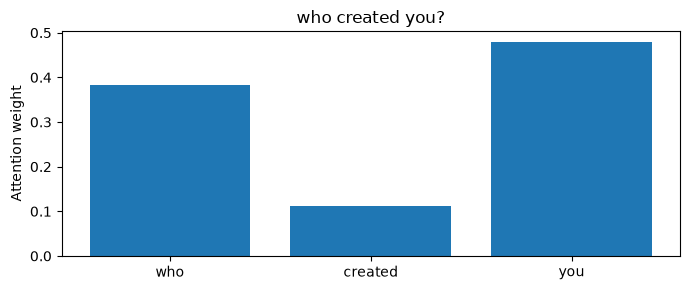

In [8]:
selected_indices = [0, 24, 48]
model.eval()

for index in selected_indices:
    token_ids = X[index][X[index] != 0].tolist()
    words = [tokenizer.index_word[token] for token in token_ids]
    with torch.no_grad():
        _, weights = model(X[index:index + 1])
    word_weights = weights[0, :len(words)].tolist()
    highest = word_weights.index(max(word_weights))
    print(f"Question: {df.loc[index, 'question']}")
    print(f"Highest attention: {words[highest]} ({word_weights[highest]:.4f})")
    plt.figure(figsize=(7, 3))
    plt.bar(words, word_weights)
    plt.title(df.loc[index, "question"])
    plt.ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

The highest-attention words are **you** in "do you get hurt?" (0.8050), **how** in "how old are you?" (0.3111), and **you** in "who created you?" (0.4792). These words help identify the subject or question type, but **hurt**, **old**, and **created** carry more of the topic-specific meaning. The highest weights therefore do not consistently identify the words that seem most important to a reader.

Each weight applies to an RNN hidden state, which also contains information from preceding words. This small model's learned attention is not a direct measure of human word importance. The original model also assigns attention to padding positions, so the displayed word weights need not sum to one.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: who programmed you?
Highest attention: who (0.7772)


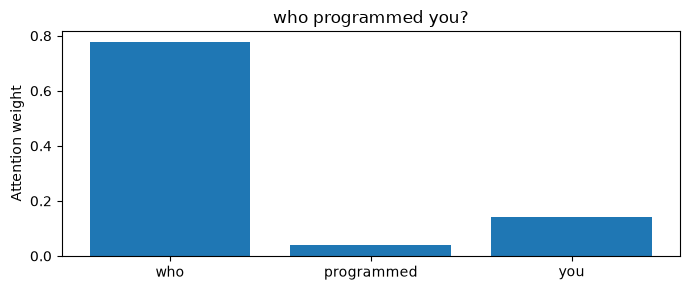

Question: who created you?
Highest attention: you (0.4792)


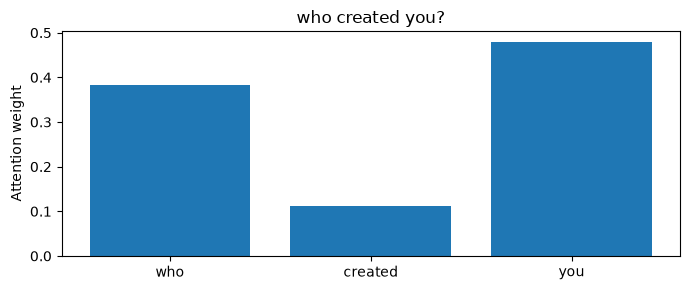

In [9]:
similar_questions = ["who programmed you?", "who created you?"]

for question in similar_questions:
    index = df.index[df["question"] == question][0]
    token_ids = X[index][X[index] != 0].tolist()
    words = [tokenizer.index_word[token] for token in token_ids]
    with torch.no_grad():
        _, weights = model(X[index:index + 1])
    word_weights = weights[0, :len(words)].tolist()
    highest = word_weights.index(max(word_weights))
    print(f"Question: {question}")
    print(f"Highest attention: {words[highest]} ({word_weights[highest]:.4f})")
    plt.figure(figsize=(7, 3))
    plt.bar(words, word_weights)
    plt.title(question)
    plt.ylabel("Attention weight")
    plt.tight_layout()
    plt.show()

The questions "who programmed you?" and "who created you?" both ask about the chatbot's creator and share the same answer group. However, the highest attention is on **who** (0.7772) in the first question and **you** (0.4792) in the second.

The model focuses on different words despite the similar meanings. Changing **programmed** to **created** changes the RNN hidden states and their attention scores. Attention is learned from the wording and context; it does not guarantee identical focus for paraphrases or human-like understanding.